# Практика 1.2. Логистическая регрессия

**Задача:** бинарная классификация — одобрит ли банк заявку на кредитную карту.

**Датасет:** [Credit Approval (UCI)](https://archive.ics.uci.edu/dataset/27/credit+approval) — 690 заявок, 15 признаков. Названия и значения признаков **анонимизированы** банком (A1…A15) для защиты персональных данных; целевая переменная A16: `+` — одобрено, `-` — отказ.

Датасет хорош для практики: в нём есть **пропуски** (обозначены `?`), **текстовые категориальные признаки** и сильно скошенные числовые признаки.

| Тип | Признаки |
|---|---|
| числовые | A2, A3, A8, A11, A14, A15 |
| категориальные | A1, A4, A5, A6, A7, A9, A10, A12, A13 |

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p1_logistic_regression"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"
TARGET = "approved"
COLUMNS = [f"A{i}" for i in range(1, 16)] + [TARGET]
NUM_COLS = ["A2", "A3", "A8", "A11", "A14", "A15"]
SKEWED_COLS = ["A3", "A8", "A11", "A14", "A15"]
CAT_COLS = ["A1", "A4", "A5", "A6", "A7", "A9", "A10", "A12", "A13"]
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


def classification_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

2026/11/10 10:03:15 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 10:03:15 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 10:03:23 INFO mlflow.tracking.fluent: Experiment with name 'p1_logistic_regression' does not exist. Creating a new experiment.


**Трекинг экспериментов.** Все запуски логируются в MLflow (база `mlflow.db` в корне репозитория).
Посмотреть результаты: из корня репозитория выполнить `mlflow ui --backend-store-uri sqlite:///mlflow.db` и открыть http://127.0.0.1:5000.

## 2. Загрузка данных
Файл без заголовка, пропуски закодированы символом `?` — сразу сообщаем об этом `read_csv`.

In [4]:
raw = pd.read_csv(download(DATA_URL, "crx.data"), header=None, names=COLUMNS, na_values="?")
df = raw.copy()
print(f"Размер: {df.shape}")
df.head()

Размер: (690, 16)


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,approved
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202.0,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43.0,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280.0,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100.0,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120.0,0,+


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   A1        678 non-null    object 
 1   A2        678 non-null    float64
 2   A3        690 non-null    float64
 3   A4        684 non-null    object 
 4   A5        684 non-null    object 
 5   A6        681 non-null    object 
 6   A7        681 non-null    object 
 7   A8        690 non-null    float64
 8   A9        690 non-null    object 
 9   A10       690 non-null    object 
 10  A11       690 non-null    int64  
 11  A12       690 non-null    object 
 12  A13       690 non-null    object 
 13  A14       677 non-null    float64
 14  A15       690 non-null    int64  
 15  approved  690 non-null    object 
dtypes: float64(4), int64(2), object(10)
memory usage: 86.4+ KB


## 3. Качество данных
### 3.1. Типы и «битые» значения
Убираем лишние пробелы в текстовых полях и приводим числовые столбцы к числу (некорректные значения станут `NaN`). Проверяем, что в категориальных признаках нет неожиданных значений.

In [6]:
for col in CAT_COLS + [TARGET]:
    df[col] = df[col].str.strip()
df[NUM_COLS] = df[NUM_COLS].apply(pd.to_numeric, errors="coerce")

for col in CAT_COLS + [TARGET]:
    print(f"{col:>8}: {df[col].value_counts(dropna=False).to_dict()}")

      A1: {'b': 468, 'a': 210, nan: 12}
      A4: {'u': 519, 'y': 163, nan: 6, 'l': 2}
      A5: {'g': 519, 'p': 163, nan: 6, 'gg': 2}
      A6: {'c': 137, 'q': 78, 'w': 64, 'i': 59, 'aa': 54, 'ff': 53, 'k': 51, 'cc': 41, 'm': 38, 'x': 38, 'd': 30, 'e': 25, 'j': 10, nan: 9, 'r': 3}
      A7: {'v': 399, 'h': 138, 'bb': 59, 'ff': 57, nan: 9, 'j': 8, 'z': 8, 'dd': 6, 'n': 4, 'o': 2}
      A9: {'t': 361, 'f': 329}
     A10: {'f': 395, 't': 295}
     A12: {'f': 374, 't': 316}
     A13: {'g': 625, 's': 57, 'p': 8}
approved: {'-': 383, '+': 307}


### 3.2. Пропуски

In [7]:
report = quality_report(df)
report[report["missing"] > 0]

,dtype,missing,missing_%,unique
A1,object,12,1.74,2
A2,float64,12,1.74,349
A4,object,6,0.87,3
A5,object,6,0.87,3
A6,object,9,1.30,14
A7,object,9,1.30,9
A14,float64,13,1.88,170


Строк хотя бы с одним пропуском: 37 (5.4%)


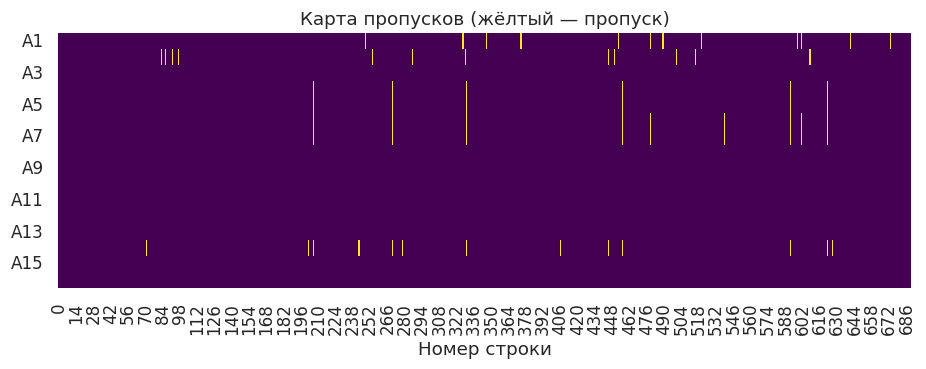

In [8]:
rows_with_na = df.isna().any(axis=1).sum()
print(f"Строк хотя бы с одним пропуском: {rows_with_na} ({rows_with_na / len(df):.1%})")

plt.figure(figsize=(10, 3))
sns.heatmap(df.isna().T, cbar=False, cmap="viridis")
plt.title("Карта пропусков (жёлтый — пропуск)")
plt.xlabel("Номер строки")
plt.show()

**Стратегия обработки пропусков:**
- строки без целевой переменной удаляем;
- строк с пропусками в признаках немного, но удалять их жалко — датасет маленький. Поэтому **заполняем**: числовые — медианой, категориальные — самым частым значением (модой).
- Заполнение выполняется **внутри Pipeline** (`SimpleImputer`): медиана и мода считаются только на обучающей выборке, а затем применяются к val/test. Так информация из тестовых данных не «утекает» в модель.

In [9]:
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df[TARGET] = df[TARGET].map({"+": 1, "-": 0}).astype(int)
df[TARGET].value_counts()

,count
approved,
0,383
1,307


### 3.3. Дубликаты

In [10]:
n_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {n_duplicates}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Размер после удаления: {df.shape}")

Полных дубликатов: 0
Размер после удаления: (690, 16)


### 3.4. Аномалии
Проверяем отрицательные значения (все числовые признаки по смыслу неотрицательны) и выбросы по IQR.

In [11]:
negatives = (df[NUM_COLS] < 0).sum()
outliers = iqr_outlier_mask(df[NUM_COLS]).sum()
skewness = df[NUM_COLS].skew()
pd.DataFrame({"отрицательных": negatives, "выбросов IQR": outliers, "асимметрия": skewness.round(2)})

,отрицательных,выбросов IQR,асимметрия
A2,0,16,1.15
A3,0,17,1.49
A8,0,63,2.89
A11,0,79,5.15
A14,0,13,2.72
A15,0,113,13.14


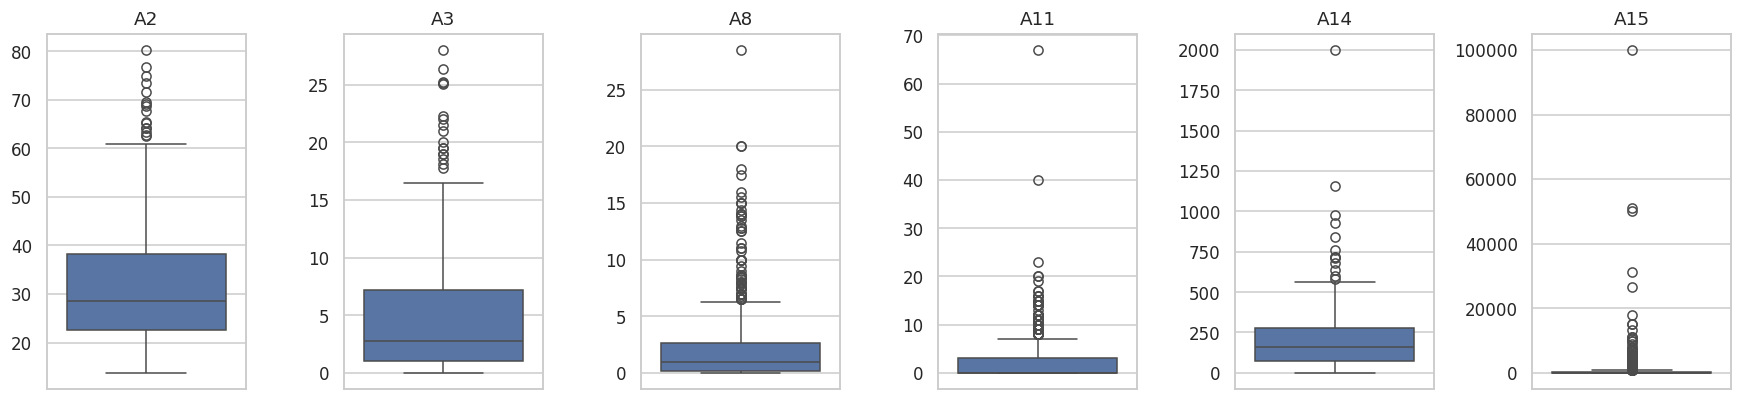

In [12]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(16, 3.8))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Стратегия:** «выбросы» здесь — не ошибки, а естественные длинные хвосты (например, A15 похож на сумму денег: у большинства 0, у немногих — очень много). Удалять их нельзя — потеряем значимую часть заявок. Вместо этого применяем **логарифмирование** `log(1 + x)` к скошенным признакам: оно сжимает хвост и делает распределение ближе к симметричному, что важно для линейной модели. Строки с отрицательными значениями (если найдутся) удаляем как битые.

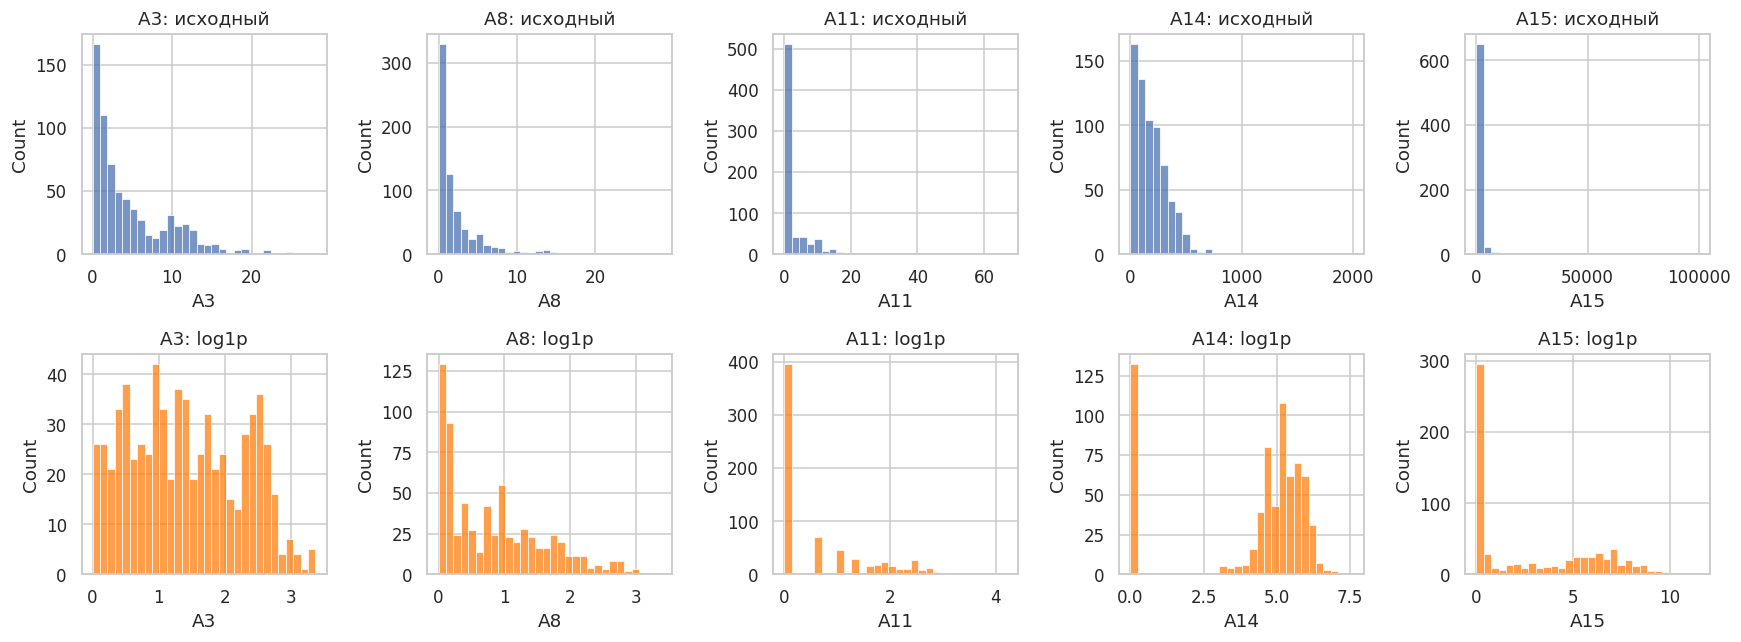

In [13]:
df = df.loc[~(df[NUM_COLS] < 0).any(axis=1)].reset_index(drop=True)

fig, axes = plt.subplots(2, len(SKEWED_COLS), figsize=(16, 6))
for i, col in enumerate(SKEWED_COLS):
    sns.histplot(df[col].dropna(), ax=axes[0, i], bins=30)
    sns.histplot(np.log1p(df[col].dropna()), ax=axes[1, i], bins=30, color="tab:orange")
    axes[0, i].set_title(f"{col}: исходный")
    axes[1, i].set_title(f"{col}: log1p")
plt.tight_layout()
plt.show()

## 4. Разведочный анализ (EDA)
### 4.1. Баланс классов и распределения

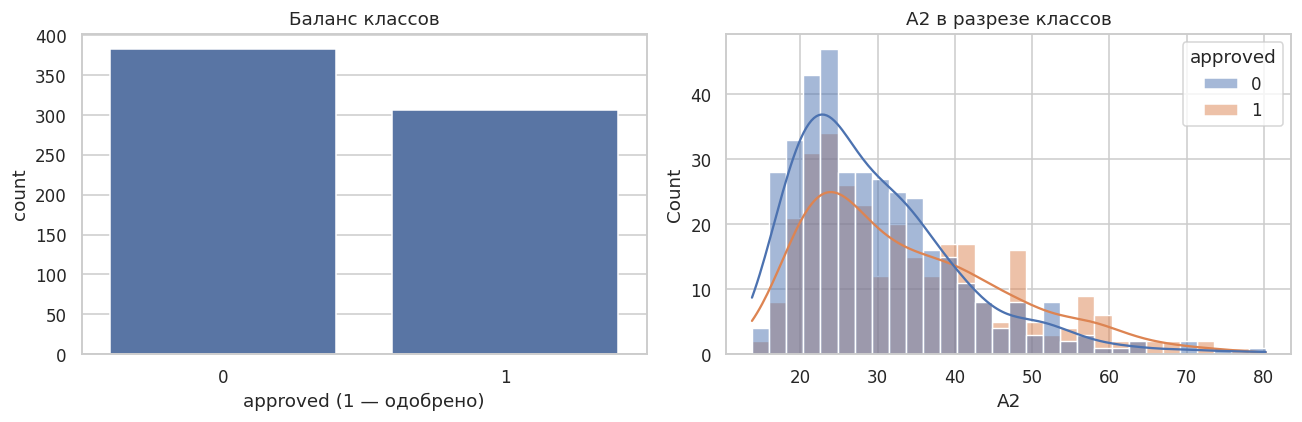

approved
0    0.555
1    0.445
Name: proportion, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df[TARGET], ax=axes[0])
axes[0].set(title="Баланс классов", xlabel="approved (1 — одобрено)")
sns.histplot(data=df, x="A2", hue=TARGET, kde=True, ax=axes[1], bins=30)
axes[1].set_title("A2 в разрезе классов")
plt.tight_layout()
plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

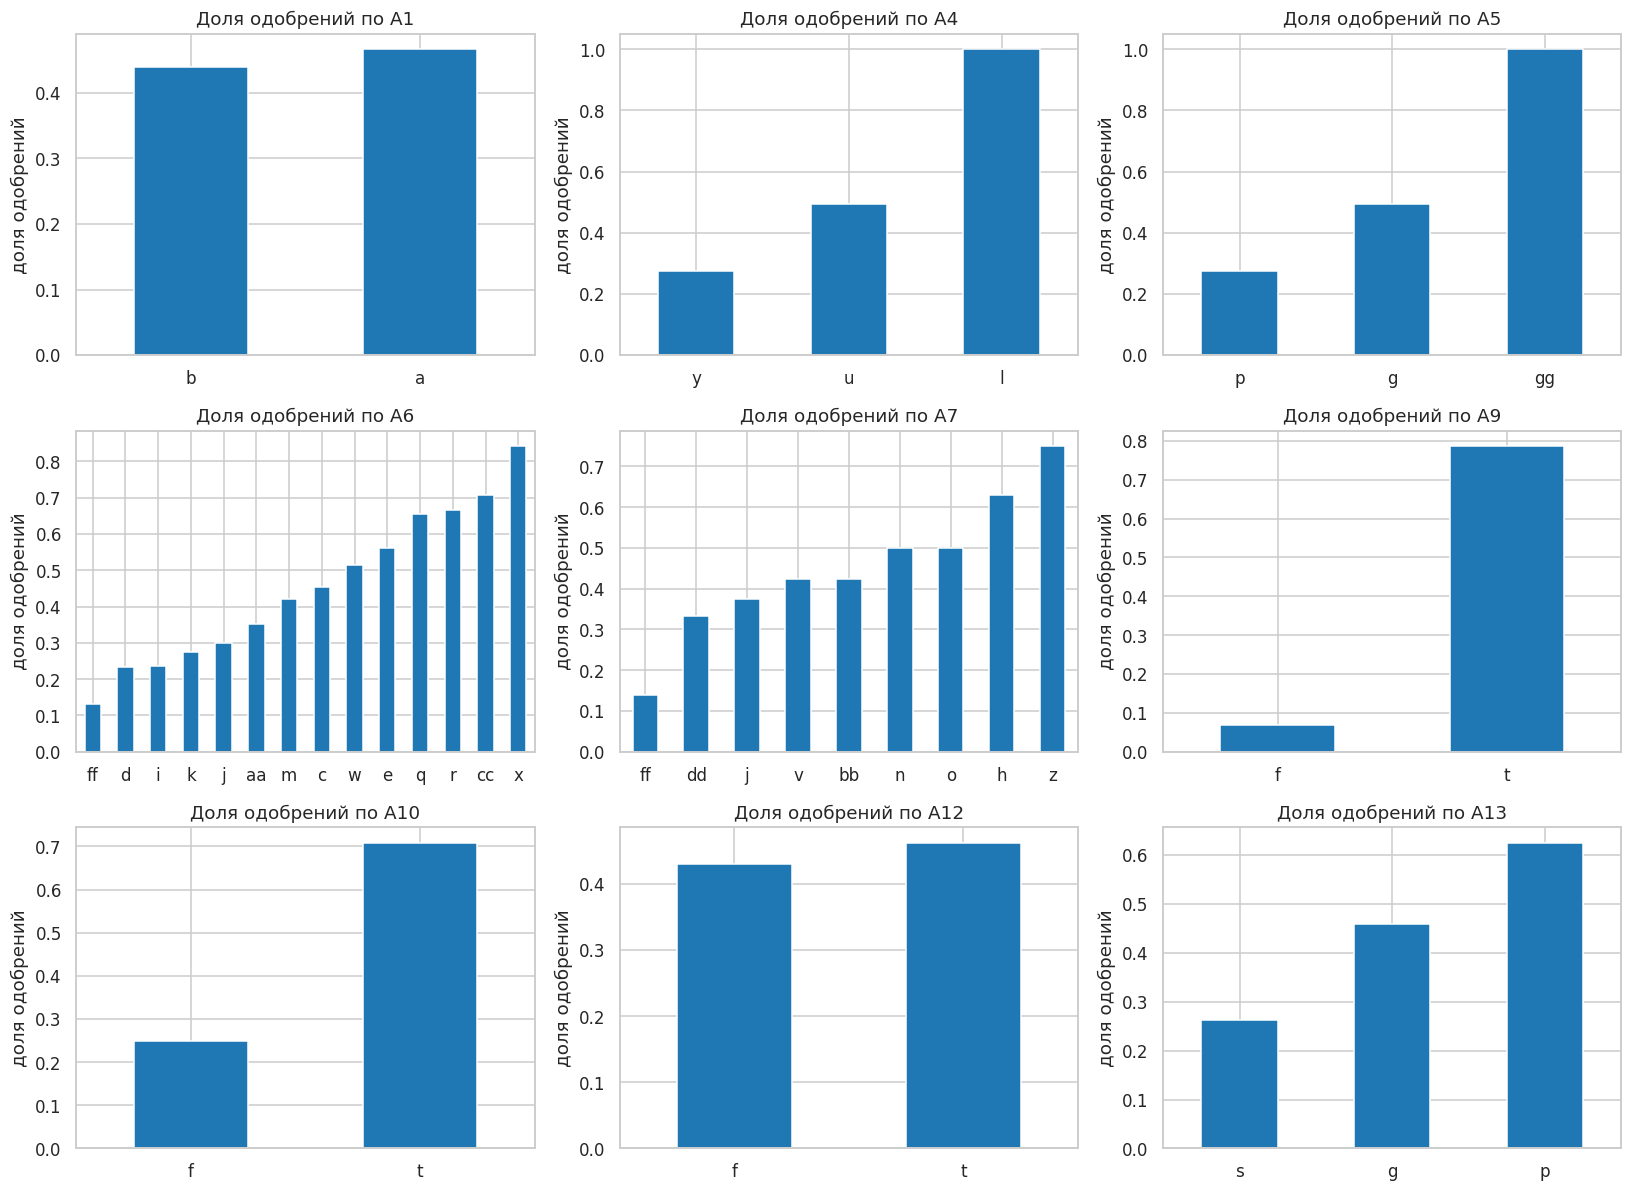

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), CAT_COLS):
    approval_rate = df.groupby(col)[TARGET].mean().sort_values()
    approval_rate.plot.bar(ax=ax, color="tab:blue")
    ax.set(title=f"Доля одобрений по {col}", ylabel="доля одобрений", xlabel="")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 4.2. Матрица корреляции
Для корреляции текстовые бинарные признаки временно переводим в 0/1, числовые скошенные — логарифмируем.

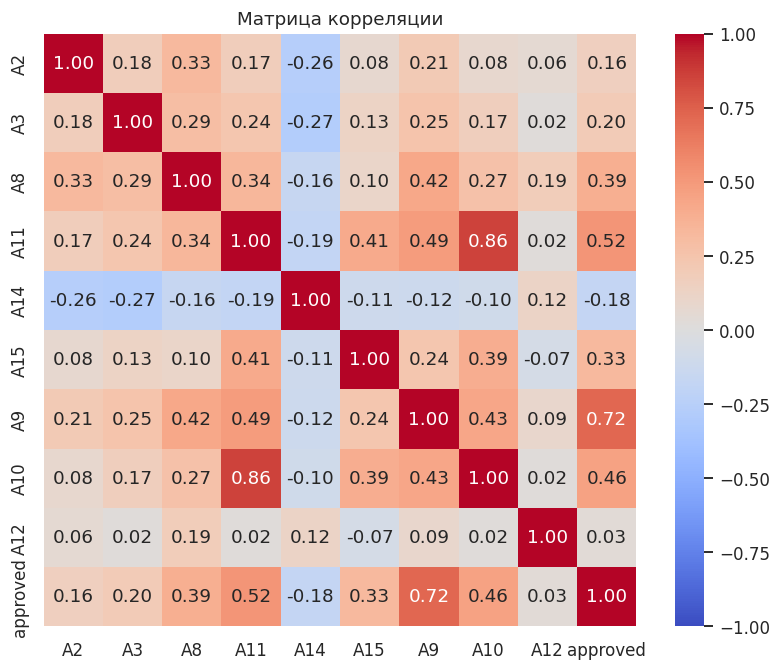

In [16]:
corr_frame = df[NUM_COLS].copy()
corr_frame[SKEWED_COLS] = np.log1p(corr_frame[SKEWED_COLS])
for col in ["A9", "A10", "A12"]:
    corr_frame[col] = df[col].map({"t": 1, "f": 0})
corr_frame[TARGET] = df[TARGET]

plt.figure(figsize=(9, 7))
sns.heatmap(corr_frame.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Матрица корреляции")
plt.show()

**Наблюдения EDA:**
- классы почти сбалансированы: 55,5 % отказов и 44,5 % одобрений, поэтому accuracy — адекватная метрика, но дополнительно смотрим F1 и ROC-AUC;
- сильнее всего с одобрением связан бинарный признак **A9** (корреляция 0,72; по исследованиям датасета — «есть ли ранее одобренные кредиты»), далее **A11** (0,52), **A10** (0,46) и **A8** (0,39);
- **A10 и A11** сильно коррелируют между собой (0,86) — вероятно, это связанные характеристики (например, «есть ли кредитная история» и её длина); для логистической регрессии с регуляризацией это допустимо;
- A12 и A14 почти не связаны с решением банка.

## 5. Подготовка признаков и разбиение
Предобработка собрана в `ColumnTransformer`:
- числовые: заполнение медианой → `log1p` для скошенных → стандартизация (логистическая регрессия с регуляризацией чувствительна к масштабу);
- категориальные: заполнение модой → **One-Hot Encoding** (текст → числовые индикаторы 0/1). `handle_unknown="ignore"` защищает от категорий, которых не было в train.

Разбиение 60/20/20 со **стратификацией** — доли классов одинаковы во всех частях.

In [17]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=SEED
)
print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

plain_num = [c for c in NUM_COLS if c not in SKEWED_COLS]


def build_model(C):
    preprocessor = ColumnTransformer([
        ("num_plain", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), plain_num),
        ("num_skewed", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ]), SKEWED_COLS),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CAT_COLS),
    ])
    return Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(C=C, max_iter=2000, random_state=SEED)),
    ])

train: 414, val: 138, test: 138


## 6. Подбор гиперпараметра на валидации
`C` — обратная сила L2-регуляризации: маленькое `C` — сильная регуляризация (простая модель), большое — слабая (риск переобучения). Перебираем сетку значений и выбираем лучшее по ROC-AUC на валидации.

In [18]:
val_rows = []
for C in C_GRID:
    model = build_model(C).fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    metrics = classification_metrics(y_val, (proba >= 0.5).astype(int), proba)
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    val_rows.append({"C": C, "train_roc_auc": train_auc, **metrics})
    with mlflow.start_run(run_name=f"logreg_C={C}"):
        mlflow.log_params({"C": C, "penalty": "l2", "seed": SEED})
        mlflow.log_metrics({f"val_{k}": v for k, v in metrics.items()})
        mlflow.log_metric("train_roc_auc", train_auc)

val_table = pd.DataFrame(val_rows).set_index("C")
best_C = val_table["roc_auc"].idxmax()
print(f"Лучшее C = {best_C}")
val_table.round(4)

Лучшее C = 3.0


,train_roc_auc,accuracy,precision,recall,f1,roc_auc
C,,,,,,
0.003,0.8947,0.8188,0.8750,0.6885,0.7706,0.8829
0.010,0.9053,0.8623,0.8889,0.7869,0.8348,0.8982
0.030,0.9163,0.8696,0.8772,0.8197,0.8475,0.9114
0.100,0.9262,0.8623,0.8500,0.8361,0.8430,0.9178
0.300,0.9335,0.8623,0.8500,0.8361,0.8430,0.9242
1.000,0.9372,0.8623,0.8500,0.8361,0.8430,0.9268
3.000,0.9395,0.8551,0.8475,0.8197,0.8333,0.9287
10.000,0.9415,0.8551,0.8475,0.8197,0.8333,0.9278


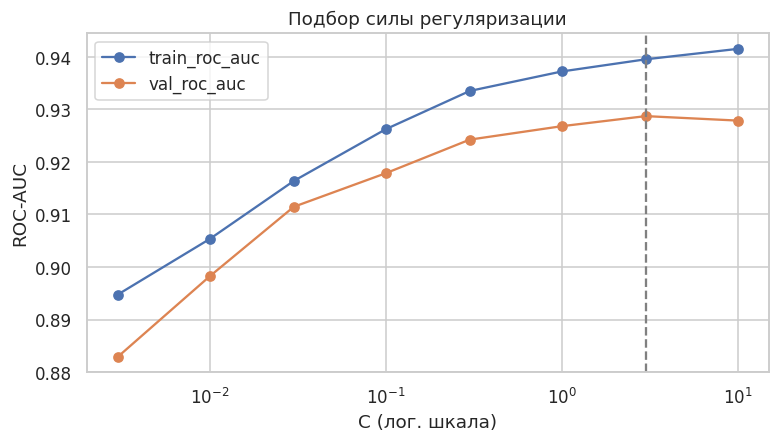

In [19]:
ax = val_table[["train_roc_auc", "roc_auc"]].rename(columns={"roc_auc": "val_roc_auc"}).plot(marker="o", logx=True, figsize=(8, 4))
ax.axvline(best_C, color="gray", linestyle="--")
ax.set(xlabel="C (лог. шкала)", ylabel="ROC-AUC", title="Подбор силы регуляризации")
plt.show()

## 7. Финальная оценка на тесте

In [20]:
final_model = build_model(best_C).fit(X_train_full, y_train_full)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)
test_metrics = classification_metrics(y_test, test_pred, test_proba)
print(classification_report(y_test, test_pred, target_names=["отказ", "одобрено"]))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

       отказ       0.89      0.92      0.90        77
    одобрено       0.90      0.85      0.87        61

    accuracy                           0.89       138
   macro avg       0.89      0.89      0.89       138
weighted avg       0.89      0.89      0.89       138



,0
accuracy,0.8913
precision,0.8966
recall,0.8525
f1,0.8739
roc_auc,0.9621


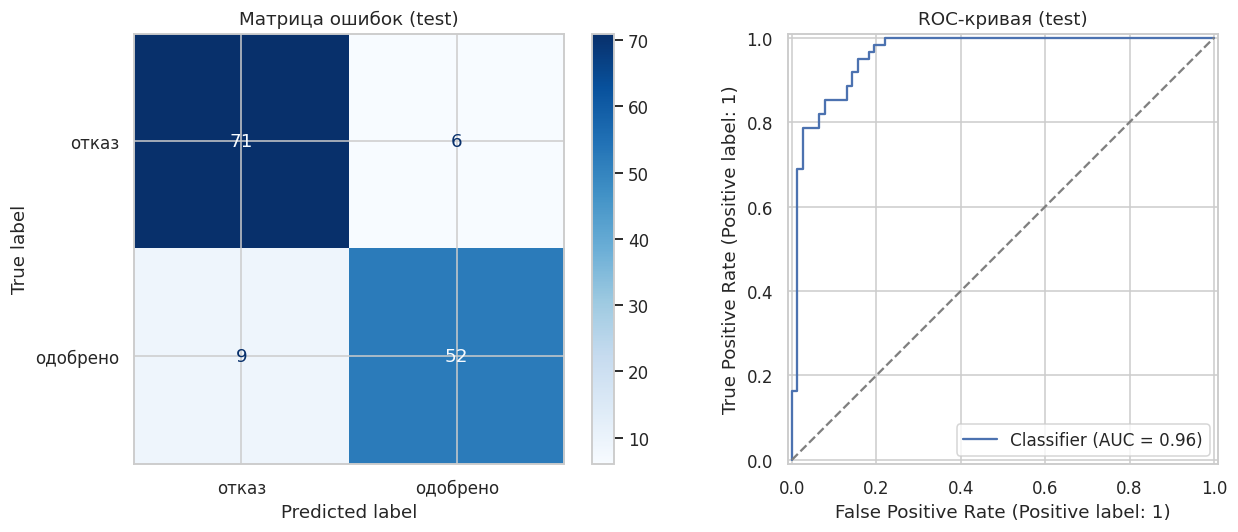

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["отказ", "одобрено"], cmap="Blues", ax=axes[0])
axes[0].set_title("Матрица ошибок (test)")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC-кривая (test)")
plt.tight_layout()
plt.show()

### Интерпретация
Коэффициент логистической регрессии — это изменение **логарифма шансов** одобрения. Положительный коэффициент повышает вероятность одобрения, отрицательный — понижает.

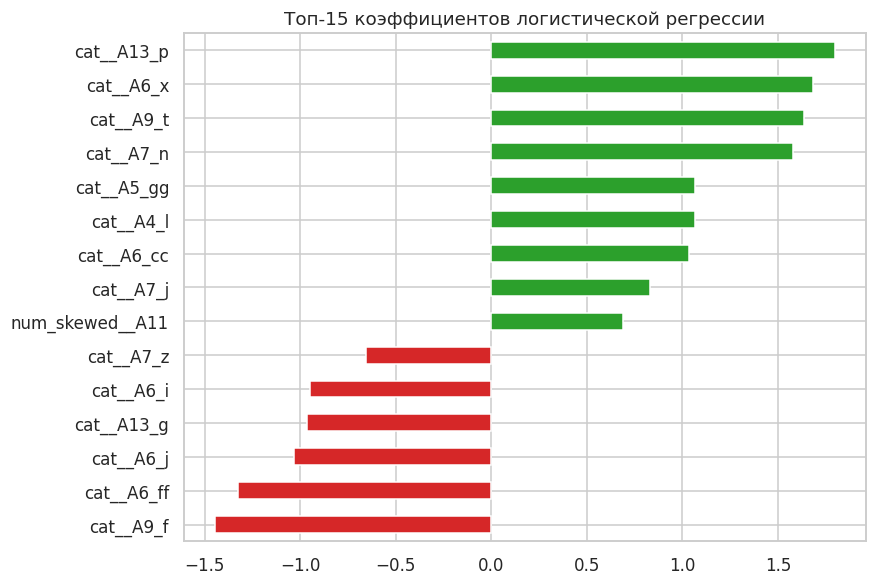

In [22]:
feature_names = final_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final_model.named_steps["clf"].coef_[0], index=feature_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:15]).sort_values()
top.plot.barh(figsize=(8, 6), color=np.where(top > 0, "tab:green", "tab:red"))
plt.title("Топ-15 коэффициентов логистической регрессии")
plt.show()

In [23]:
with mlflow.start_run(run_name="logreg_final"):
    mlflow.log_params({"C": best_C, "penalty": "l2", "n_train": len(X_train_full), "seed": SEED})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "confusion_matrix_and_roc.png")
print("Финальный запуск записан в MLflow")

Финальный запуск записан в MLflow


## 8. Выводы
- **Качество данных.** В 690 заявках найдено 37 строк (5,4 %) с пропусками в признаках A1, A2, A4–A7, A14 (по 6–13 пропусков в каждом). Строки не удалялись: пропуски заполнены медианой (числовые) и модой (категориальные) внутри Pipeline, без утечки из теста. Дубликатов и отрицательных значений нет. Признаки A11 и A15 оказались сильно скошены (асимметрия 5,2 и 13,1) — выбросы оставлены как реальные значения и сглажены логарифмированием.
- **Кодирование.** 9 текстовых признаков закодированы One-Hot, целевая переменная `+`/`-` → 1/0.
- **Подбор модели.** Лучшая сила регуляризации на валидации — **C = 3** (ROC-AUC 0,929). ROC-AUC на train (0,940) лишь немного выше валидационного — модель не переобучена; при C < 0,03 качество заметно падает (недообучение).
- **Итог на тесте (138 заявок):** accuracy **0,891**, precision **0,897**, recall **0,853**, F1 **0,874**, ROC-AUC **0,962**. Модель чаще ошибается, отказывая надёжному клиенту (recall для «одобрено» 0,85), чем одобряя ненадёжного (recall для «отказ» 0,92) — для банка это более безопасный тип ошибки.
- **Интерпретация.** Самый важный и устойчивый признак — **A9**: значение `t` сильно повышает шанс одобрения, `f` — понижает; положительно влияет и A11. Крупные коэффициенты у редких категорий (например, A13 = `p` встречается всего 8 раз) статистически ненадёжны — их не стоит интерпретировать как закономерность.